# Read and filter LMSYS-CHAT-1M

- Dataset - https://huggingface.co/datasets/lmsys/lmsys-chat-1m
- Paper - https://arxiv.org/abs/2309.11998

In [1]:
import pandas as pd
import os

In [2]:
sorted(os.listdir('./lmsys-chat-1m/'))

['train-00000-of-00006-4feeb3f83346a0e9.parquet',
 'train-00001-of-00006-4030672591c2f478.parquet',
 'train-00002-of-00006-1779b7cec9462180.parquet',
 'train-00003-of-00006-2fa862bfed56af1f.parquet',
 'train-00004-of-00006-18f4bdd50c103e71.parquet',
 'train-00005-of-00006-fe1acc5d10a9f0e2.parquet']

In [3]:
dfs = []

for fn in sorted(os.listdir('./lmsys-chat-1m/')):
    
    dfs.append(
        pd.read_parquet(f'lmsys-chat-1m/{fn}')
            .query('language == "English"')
    )

data_en = pd.concat(dfs)

In [4]:
#data[data.conversation_id == "e5c923a7fa3f4893beb432b4a06ef222"]['conversation'].iloc[0]
#data

count    777453.000000
mean        354.860666
std         542.362258
min           1.000000
25%          47.000000
50%         117.000000
75%         399.000000
max        2882.000000
Name: first_turn_len, dtype: float64

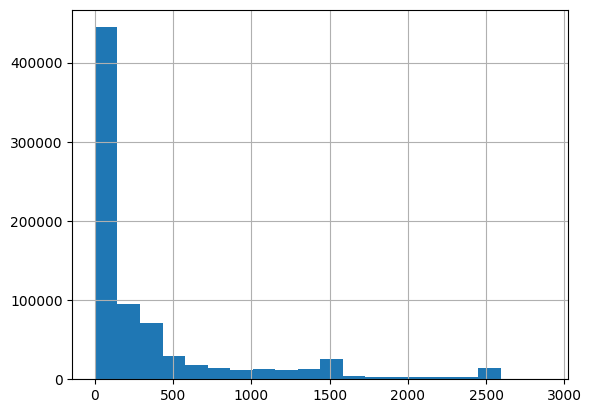

In [5]:
data = data_en.assign(
    first_turn=lambda df_: df_.conversation.apply(lambda x: x[0]['content'].strip()),
    first_turn_len=lambda df_: df_.first_turn.str.len()
)

data.first_turn_len.hist(bins=20)
data.first_turn_len.describe()

In [13]:
data.first_turn_len.le(131).mean().round(3)

0.541

In [6]:
data

,conversation_id,model,conversation,turn,language,openai_moderation,redacted,first_turn,first_turn_len
0,33f01939a744455c869cb234afca47f1,wizardlm-13b,[{'content': 'how can identity protection serv...,1,English,"[{'categories': {'harassment': False, 'harassm...",False,how can identity protection services help prot...,75
1,1e230e55efea4edab95db9cb87f6a9cb,vicuna-13b,[{'content': 'Beside OFAC's selective sanction...,6,English,"[{'categories': {'harassment': False, 'harassm...",False,Beside OFAC's selective sanction that target t...,227
2,0f623736051f4a48a506fd5933563cfd,vicuna-13b,[{'content': 'You are the text completion mode...,1,English,"[{'categories': {'harassment': False, 'harassm...",False,You are the text completion model and you must...,419
3,e5c923a7fa3f4893beb432b4a06ef222,palm-2,[{'content': 'The sum of the perimeters of thr...,2,English,"[{'categories': {'harassment': False, 'harassm...",False,The sum of the perimeters of three equal squar...,139
4,8ad66650dced4b728de1d14bb04657c1,vicuna-13b,[{'content': 'What is the type of the variable...,1,English,"[{'categories': {'harassment': False, 'harassm...",False,What is the type of the variables in the follo...,136
...,...,...,...,...,...,...,...,...,...
166659,5819035372b744f7891d5bed484fe37e,vicuna-13b,"[{'content': 'hi! what's up', 'role': 'user'},...",4,English,"[{'categories': {'harassment': False, 'harassm...",False,hi! what's up,13
166660,d9d265b07f1d472089b3d9d634abfebb,claude-1,"[{'content': 'Scrivi hello world in python', '...",1,English,"[{'categories': {'harassment': False, 'harassm...",False,Scrivi hello world in python,28
166662,42458cc230c34c02ad2fede8190434d5,vicuna-13b,"[{'content': 'hello', 'role': 'user'}, {'conte...",3,English,"[{'categories': {'harassment': False, 'harassm...",False,hello,5
166663,f3e0b1837dd74305bec5eac0d78d0ec7,vicuna-13b,[{'content': '### Instruction: Extract causal ...,1,English,"[{'categories': {'harassment': False, 'harassm...",True,### Instruction: Extract causal economic narra...,1249


## For this study only, let's remove long first turns

- The idea is to use the same query classifier to identify geospatial intent/question that was trained on MS MARCO
- So we have to get turns that resemble search queries; in the MS MARCO Geospatial paper, 99.9% of queries are under 131 characters

In [17]:
print('Before removing long first turns:', data.shape[0])
data = data.query('first_turn_len <= 131')
print('After removing long first turns:', data.shape[0])

Before removing long first turns: 777453
After removing long first turns: 420804


In [18]:
data

,conversation_id,model,conversation,turn,language,openai_moderation,redacted,first_turn,first_turn_len
0,33f01939a744455c869cb234afca47f1,wizardlm-13b,[{'content': 'how can identity protection serv...,1,English,"[{'categories': {'harassment': False, 'harassm...",False,how can identity protection services help prot...,75
13,e3addcd33c9d42b2be07c4bbbf9ce92e,llama-2-13b-chat,[{'content': 'how many floors does the burj al...,6,English,"[{'categories': {'harassment': False, 'harassm...",True,how many floors does the burj al arab have,42
18,44dff9cfb93f48ff92ef0625a642ad04,alpaca-13b,[{'content': 'for all the reasons you might at...,1,English,"[{'categories': {'harassment': False, 'harassm...",False,for all the reasons you might attend a youth b...,93
20,c4dd5dbd4cdf4b0ab138c0af3be8066a,koala-13b,[{'content': 'Scrape git hub for the best comb...,6,English,"[{'categories': {'harassment': False, 'harassm...",True,Scrape git hub for the best combination of a r...,92
21,12096847004d488784e1e339f200da88,vicuna-13b,[{'content': 'How many terms can the president...,1,English,"[{'categories': {'harassment': False, 'harassm...",False,How many terms can the president hold office i...,56
...,...,...,...,...,...,...,...,...,...
166655,e0032d2907a24a24a40403e0b5ab7611,koala-13b,"[{'content': 'hello', 'role': 'user'}, {'conte...",4,English,"[{'categories': {'harassment': False, 'harassm...",False,hello,5
166658,6ee6c26633e8449c9832221f6cca4588,mpt-7b-chat,"[{'content': 'What is the MPAA rating for ""Kin...",1,English,"[{'categories': {'harassment': False, 'harassm...",False,"What is the MPAA rating for ""Kindergarten Cop""?",47
166659,5819035372b744f7891d5bed484fe37e,vicuna-13b,"[{'content': 'hi! what's up', 'role': 'user'},...",4,English,"[{'categories': {'harassment': False, 'harassm...",False,hi! what's up,13
166660,d9d265b07f1d472089b3d9d634abfebb,claude-1,"[{'content': 'Scrivi hello world in python', '...",1,English,"[{'categories': {'harassment': False, 'harassm...",False,Scrivi hello world in python,28


## Remove duplicates

- Dataset is messy, so just look at country+first turn text 

In [21]:
print('Before deduplication:', data.shape[0])
data = data.drop_duplicates(subset=['first_turn', 'model'])
print('After deduplication:', data.shape[0])

Before deduplication: 420804
After deduplication: 350847


## Save

- At this stage we only care about the actual text, not the model or timestamp
- Let's create conversation ID as `'lmsyschat::\<conversation_id\>'`

In [25]:
data.assign(
    conv_id=lambda df_: 'lmsyschat::' + df_.conversation_id
).filter(
    ['conv_id', 'first_turn']
).to_csv('interim/lmsyschat.first_turn.en.len131.csv.zip')